# 05_default_risk_model

## Ziel
In diesem Notebook wird ein Modell zur Vorhersage von Kreditausfällen (`default`) erstellt.

Die Eingabedatei stammt aus `04_scoring_comparison.ipynb` und wird manuell hochgeladen.
Dabei werden insbesondere folgende Variablen untersucht:

- finanzielle Merkmale
- alter Score (`old_score`)
- neuer Score (`new_score`)
- tatsächlicher Kreditausfall (`default`)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [5]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

try:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=",")
except:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=";")

print("Datei geladen:", file_name)
df.head()

Saving scoring_comparison_results.csv to scoring_comparison_results.csv
Datei geladen: scoring_comparison_results.csv


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,...,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default,debt_to_income_clean,income_to_loan_ratio,old_score_final,new_score_final,score_diff
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,...,100.0,100.0,1,1,0,5.002081,0.199782,0.000000,64.614034,64.614034
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,...,100.0,100.0,0,1,0,5.668430,0.176354,0.000000,17.084072,17.084072
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,...,93.8,100.0,1,1,1,4.337272,0.230480,0.000000,0.000000,0.000000
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,...,98.6,100.0,1,1,0,2.362900,0.422939,25.209555,0.000000,-25.209555
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,...,96.7,99.4,1,1,0,4.501437,0.222006,0.000000,108.599722,108.599722


In [6]:
print("Shape:", df.shape)
print("\nSpalten:")
print(df.columns.tolist())

Shape: (10000, 26)

Spalten:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default', 'debt_to_income_clean', 'income_to_loan_ratio', 'old_score_final', 'new_score_final', 'score_diff']


In [7]:
df["default"].value_counts()

,count
default,
0,8699
1,1301


In [8]:
df["default"].value_counts(normalize=True) * 100

,proportion
default,
0,86.99
1,13.01


Hier prüfen wir, wie viele Kreditausfälle (`default = 1`) und Nicht-Ausfälle (`default = 0`) enthalten sind.

In [9]:
target = "default"

features = [
    "age",
    "net_income",
    "employment_status",
    "marital_status",
    "dependents",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score"
]

df_model = df[features + [target]].copy()
df_model = df_model.dropna()

df_model.head()

,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,default
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,1,9.2,0,0,4301.25,5.03,100.0,100.0,0
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,0,9.6,0,0,3233.97,2.04,100.0,100.0,0
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,2,10.8,0,0,-409.95,-0.16,93.8,100.0,1
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,2,5.6,0,0,-1898.47,-1.78,98.6,100.0,0
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,1,8.6,0,0,1761.98,1.31,96.7,99.4,0


In [10]:
X = df_model.drop(columns=[target])
y = df_model[target]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerische Features:")
print(numeric_features)

print("\nKategoriale Features:")
print(categorical_features)

Numerische Features:
['age', 'net_income', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score']

Kategoriale Features:
['employment_status', 'marital_status']


In [11]:
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

print("Shape nach Encoding:", X_encoded.shape)
X_encoded.head()

Shape nach Encoding: (10000, 21)


,age,net_income,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,...,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,employment_status_arbeitslos,employment_status_selbstständig,employment_status_teilzeit,marital_status_ledig,marital_status_verheiratet
0,56,1777.14,0,855.64,2,8894.40,0.42,0,1,9.2,...,0,4301.25,5.03,100.0,100.0,False,True,False,False,True
1,69,3370.44,0,1584.98,1,19110.77,0.47,0,0,9.6,...,0,3233.97,2.04,100.0,100.0,False,False,True,False,True
2,46,3558.95,0,2547.68,1,15440.47,0.36,2,2,10.8,...,0,-409.95,-0.16,93.8,100.0,True,False,False,False,False
3,32,2230.99,0,1066.70,1,5273.97,0.20,0,2,5.6,...,0,-1898.47,-1.78,98.6,100.0,False,True,False,True,False
4,60,1873.87,1,1343.87,3,8439.61,0.38,2,1,8.6,...,0,1761.98,1.31,96.7,99.4,False,False,True,True,False


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (8000, 21)
X_test: (2000, 21)


In [37]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [39]:
y_pred_log = log_model.predict(X_test_scaled)
y_proba_log = log_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-Score:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_log))

Accuracy: 0.659
Precision: 0.20612813370473537
Recall: 0.5692307692307692
F1-Score: 0.30265848670756645
ROC-AUC: 0.6747833775419982


In [40]:
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.91      0.67      0.77      1740
           1       0.21      0.57      0.30       260

    accuracy                           0.66      2000
   macro avg       0.56      0.62      0.54      2000
weighted avg       0.82      0.66      0.71      2000



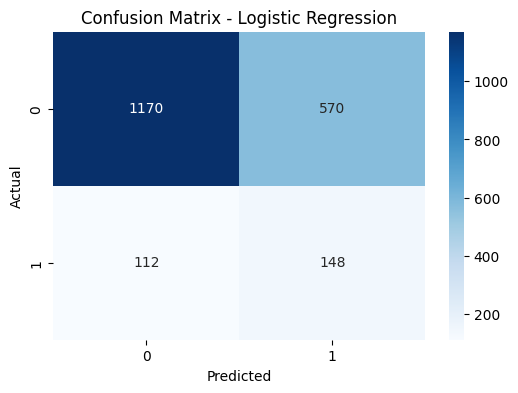

In [41]:
cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

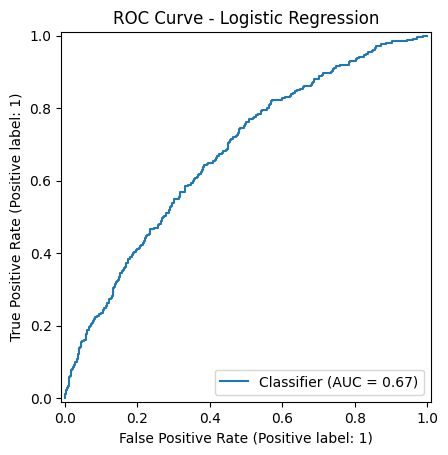

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt
from google.colab import files

# Plot erstellen
RocCurveDisplay.from_predictions(y_test, y_proba_log)
plt.title("ROC Curve - Logistic Regression")

# Datei lokal (in Colab) speichern
file_name = "roc_curve_logistic_regression.png"
plt.savefig(file_name, bbox_inches="tight")

plt.show()

# 👉 AUTOMATISCH DOWNLOAD STARTEN
files.download(file_name)

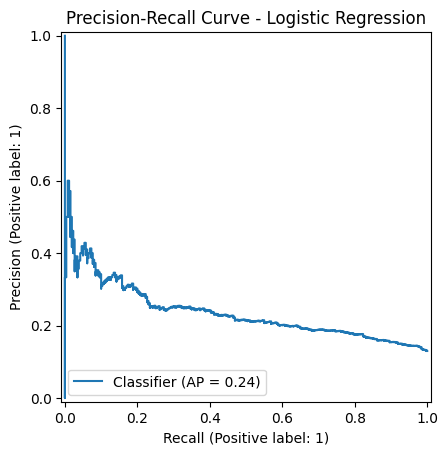

In [43]:
PrecisionRecallDisplay.from_predictions(y_test, y_proba_log)
plt.title("Precision-Recall Curve - Logistic Regression")
plt.show()

In [23]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=5,
                       min_samples_split=10, n_estimators=200, random_state=42)

In [45]:
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

Accuracy: 0.747
Precision: 0.24586776859504134
Recall: 0.4576923076923077
F1-Score: 0.31989247311827956
ROC-AUC: 0.7055327144120247


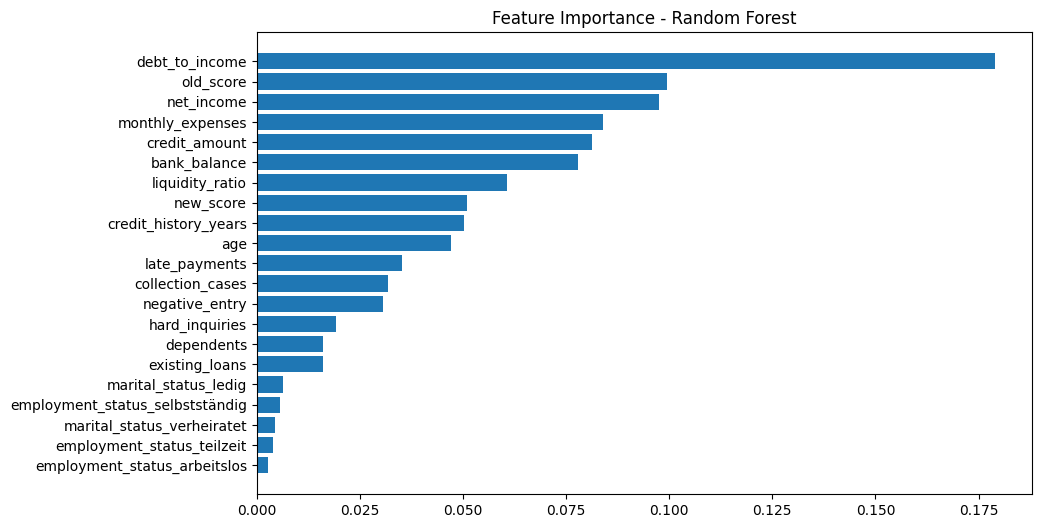

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

importance = rf_model.feature_importances_
features = X_train.columns

df_importance = pd.DataFrame({
    "feature": features,
    "importance": importance
}).sort_values(by="importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(df_importance["feature"], df_importance["importance"])

plt.title("Feature Importance - Random Forest")

file_name = "feature_importance_random_forest.png"
plt.savefig(file_name, bbox_inches="tight")

plt.show()

files.download(file_name)

In [25]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.91      0.79      0.84      1740
           1       0.25      0.46      0.32       260

    accuracy                           0.75      2000
   macro avg       0.58      0.62      0.58      2000
weighted avg       0.82      0.75      0.78      2000



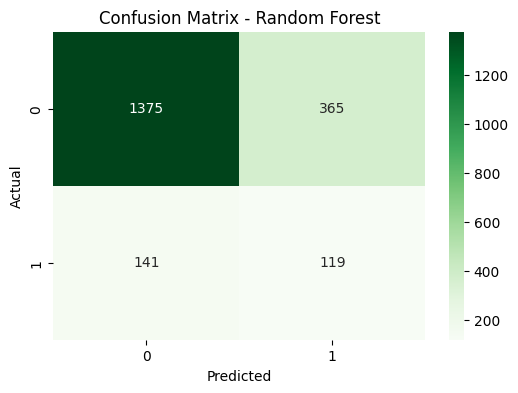

In [26]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [27]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_log),
        roc_auc_score(y_test, y_proba_rf)
    ]
})

comparison.sort_values("ROC-AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Random Forest,0.747,0.245868,0.457692,0.319892,0.705533
0,Logistic Regression,0.659,0.206128,0.569231,0.302658,0.674783


In [28]:
feature_importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance_df.head(15)

,feature,importance
6,debt_to_income,0.178939
14,old_score,0.099403
1,net_income,0.097416
3,monthly_expenses,0.083968
5,credit_amount,0.081373
12,bank_balance,0.077975
13,liquidity_ratio,0.060599
15,new_score,0.050988
9,credit_history_years,0.050135
0,age,0.046992


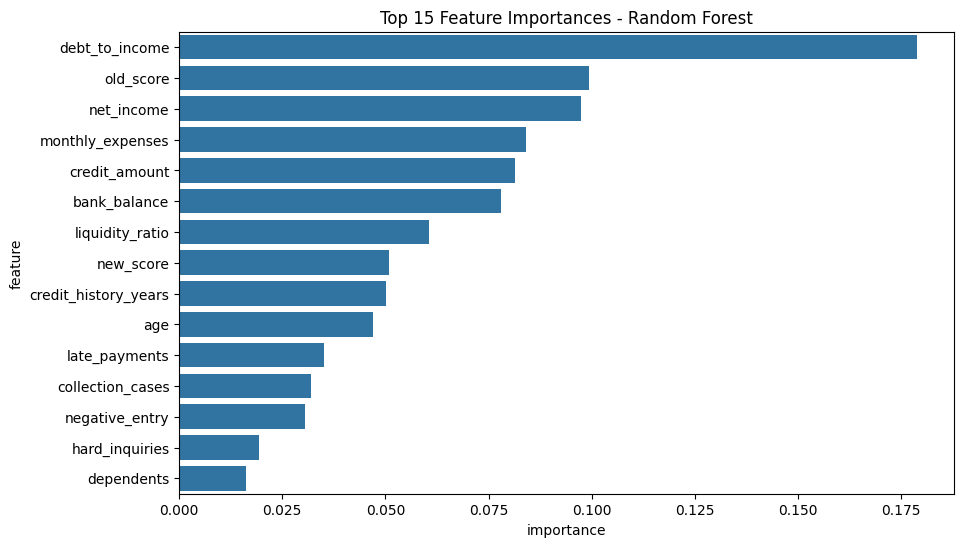

In [29]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="importance", y="feature")
plt.title("Top 15 Feature Importances - Random Forest")
plt.show()

In [30]:
features_old = [
    "age",
    "net_income",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "old_score"
]

df_old = df[features_old + [target]].dropna()

X_old = df_old.drop(columns=[target])
y_old = df_old[target]

cat_old = X_old.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
X_old = pd.get_dummies(X_old, columns=cat_old, drop_first=True)

X_train_old, X_test_old, y_train_old, y_test_old = train_test_split(
    X_old, y_old, test_size=0.2, random_state=42, stratify=y_old
)

scaler_old = StandardScaler()
X_train_old_scaled = scaler_old.fit_transform(X_train_old)
X_test_old_scaled = scaler_old.transform(X_test_old)

model_old = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model_old.fit(X_train_old_scaled, y_train_old)

y_proba_old = model_old.predict_proba(X_test_old_scaled)[:, 1]
roc_old = roc_auc_score(y_test_old, y_proba_old)

print("ROC-AUC altes Score-Modell:", roc_old)

ROC-AUC altes Score-Modell: 0.6788395225464191


In [31]:
features_new = [
    "age",
    "net_income",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "new_score"
]

df_new = df[features_new + [target]].dropna()

X_new = df_new.drop(columns=[target])
y_new = df_new[target]

cat_new = X_new.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
X_new = pd.get_dummies(X_new, columns=cat_new, drop_first=True)

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2, random_state=42, stratify=y_new
)

scaler_new = StandardScaler()
X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

model_new = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model_new.fit(X_train_new_scaled, y_train_new)

y_proba_new = model_new.predict_proba(X_test_new_scaled)[:, 1]
roc_new = roc_auc_score(y_test_new, y_proba_new)

print("ROC-AUC neues Score-Modell:", roc_new)

ROC-AUC neues Score-Modell: 0.6803249336870026


In [32]:
score_comparison = pd.DataFrame({
    "Version": ["Old Score Model", "New Score Model"],
    "ROC-AUC": [roc_old, roc_new]
})

score_comparison

,Version,ROC-AUC
0,Old Score Model,0.678840
1,New Score Model,0.680325


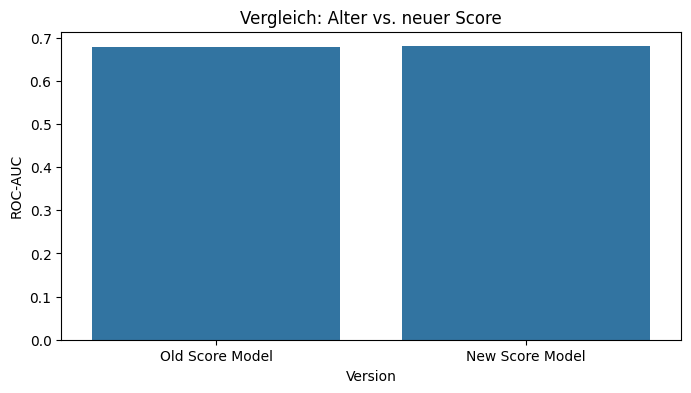

In [33]:
plt.figure(figsize=(8, 4))
sns.barplot(data=score_comparison, x="Version", y="ROC-AUC")
plt.title("Vergleich: Alter vs. neuer Score")
plt.show()

# Interpretation der Ergebnisse

## Mögliche Erkenntnisse
- Der neue Score kann eine bessere Risikodifferenzierung liefern, wenn Liquidität stärker berücksichtigt wird.
- Der alte Score gewichtet möglicherweise klassische Negativmerkmale stärker.
- Für die Ausfallvorhersage ist nicht nur der Score relevant, sondern auch:
  - Einkommen
  - Schuldenquote
  - Kontostand
  - Liquidität
  - bisheriges Zahlungsverhalten

## Projektaussage
Eine Person mit schwächerem Score kann trotzdem kreditwürdig sein, wenn reale Finanzkennzahlen stabil sind.
Gleichzeitig können Personen mit scheinbar akzeptablem Score, aber schwacher Liquidität und hoher Belastung, ein erhöhtes Ausfallrisiko haben.